In [46]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-10-04 12:45:59--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv.3’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.03s   

2026-10-04 12:46:00 (23.1 MB/s) - ‘car_fuel_efficiency_2026.csv.3’ saved [635180/635180]



In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
base = ['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']
df = df[base]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

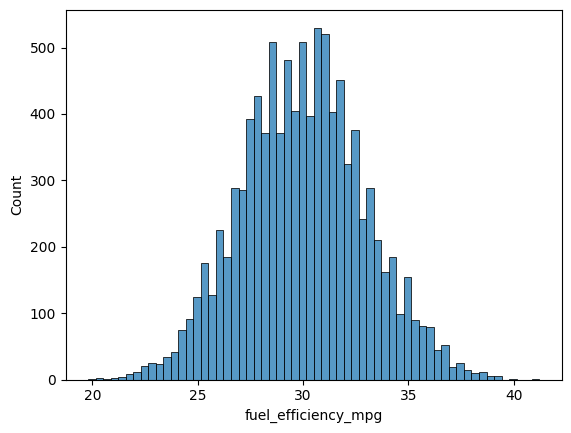

In [34]:
sns.histplot(df['fuel_efficiency_mpg'])

# Q-**1**

In [35]:
df.isnull().sum() #horsepower

,0
engine_displacement,0
horsepower,877
vehicle_weight,0
model_year,0
fuel_efficiency_mpg,0


# Q-**2**

In [36]:
df['horsepower'].median()

254.0

# prepare and split the **dataset**

In [49]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# **Q-3**

In [50]:
def train_linear_regression(x, y):
    ones = np.ones(x.shape[0])
    x = np.column_stack([ones, x])
    xtx = x.T.dot(x)
    xtx_inv = np.linalg.inv(xtx)
    w_full = xtx_inv.dot(x.T).dot(y)
    return w_full[0], w_full[1:]
# fillna(0)
x_train0 = df_train.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
y_train = df_train['fuel_efficiency_mpg'].values
x_val0 = df_val.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
y_val = df_val['fuel_efficiency_mpg'].values
w0, w = train_linear_regression(x_train0, y_train)
y_pred0 = w0 + x_val0.dot(w)



In [39]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)
score0 = rmse(y_val, y_pred0)
round(score0, 3)


np.float64(0.071)

In [40]:
hp_mean = df_train['horsepower'].mean()

In [41]:
x_train_mean = df_train.drop('fuel_efficiency_mpg', axis=1).fillna(hp_mean).values
x_val_mean = df_val.drop('fuel_efficiency_mpg', axis=1).fillna(hp_mean).values
w0, w = train_linear_regression(x_train_mean, y_train)
y_pred_mean = w0 + x_val_mean.dot(w)
score_mean = rmse(y_val, y_pred_mean)
round(score_mean, 3)

np.float64(0.071)

# Q-**4**

In [42]:
def train_linear_regression_reg(x, y, r=0.001):
    ones = np.ones(x.shape[0])
    x = np.column_stack([ones, x])
    xtx = x.T.dot(x)
    regs = r * np.eye(xtx.shape[0])
    regs[0, 0] = 0
    xtx = xtx + regs
    xtx = xtx + regs
    xtx_inv = np.linalg.inv(xtx)
    w_full = xtx_inv.dot(x.T).dot(y)
    return w_full[0], w_full[1:]


In [43]:
x_train = df_train.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
x_val = df_val.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
scores = []
for i in [0, 0.01, 0.1, 1, 5, 10, 100]:
  w0, w = train_linear_regression_reg(x_train, y_train, i)
  y_pred = w0 + x_val.dot(w)
  score = rmse(y_val, y_pred)
  scores.append(round(score, 4))
  print(i, round(score, 4))
min(scores)

0 0.0715
0.01 0.0715
0.1 0.0715
1 0.0715
5 0.0715
10 0.0715
100 0.0715


np.float64(0.0715)

# Q-**5**

In [60]:
features = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year",
]
target = "fuel_efficiency_mpg"


seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []


for s in seeds:
  np.random.seed(s)

  idx = np.arange(n)
  np.random.shuffle(idx)

  df_shuffled = df.iloc[idx].copy()

  df_train = df_shuffled.iloc[:n_train]
  df_val = df_shuffled.iloc[n_train : n_train + n_val]

  y_train = df_train[target].values
  y_val = df_val[target].values

  X_train = df_train[features].fillna(0).values
  X_val = df_val[features].fillna(0).values

  w0, w = train_linear_regression(X_train, y_train)
  y_pred = w0 + X_val.dot(w)

  score = rmse(y_val, y_pred)
  scores.append(score)


std_value = round(np.std(scores), 3)
std_value


np.float64(0.029)

# Q-**6**

In [59]:
n9 = len(df)
n_val9 = int(n9 * 0.2)
n_test9 = int(n9 * 0.2)
n_train9 = n9 - n_val9 - n_test9
np.random.seed(9)
idx9 = np.arange(n)
np.random.shuffle(idx)
df_train9 = df.iloc[idx[:n_train9]]
df_val9 = df.iloc[idx[n_train9:n_train9+n_val9]]
df_test9 = df.iloc[idx[n_train9+n_val9:]]
df_train9 = df_train9.reset_index(drop=True)
df_val9 = df_val9.reset_index(drop=True)
df_test9 = df_test9.reset_index(drop=True)


x_test9 = df_test9.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
y_test9 = df_test9['fuel_efficiency_mpg'].values
df_full_train = pd.concat([df_train9, df_val9])
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train['fuel_efficiency_mpg'].values
x_full_train = df_full_train.drop('fuel_efficiency_mpg', axis=1).fillna(0).values
w0, w = train_linear_regression_reg(x_full_train, y_full_train, 0.001)
y_pred_test = w0 + x_test9.dot(w)
score = rmse(y_test9, y_pred_test)
score


np.float64(2.2362507780023155)